# 01 · Data: integrity and preprocessing

**Question.** Is the data read exactly as supplied, and what happens to it before modelling?

**Answer.**
- All 86 integrity checks pass, including an exact match with the platform's own daily quote counts.
- 25,000 quotes; 23,556 have a known ending. The 1,444 marked "open" expired months before the
  extract and are excluded.
- Sending time is heavily skewed and enters the model on a log scale. The quote amount is a fair
  proxy for job value (within 3%).

In [1]:
import sys

sys.path.insert(0, "../scripts")

import explore
import figures
import pandas as pd
import style
from IPython.display import Image, display

from quote_followup.config import load_settings
from quote_followup.data import load_quotes

pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 100)
style.apply()
settings = load_settings("../config.toml")
quotes = load_quotes(settings.data_dir)

import os
from pathlib import Path

from quote_followup import audit

## 1. Schema

Every record belongs to one business; all links are checked within it.

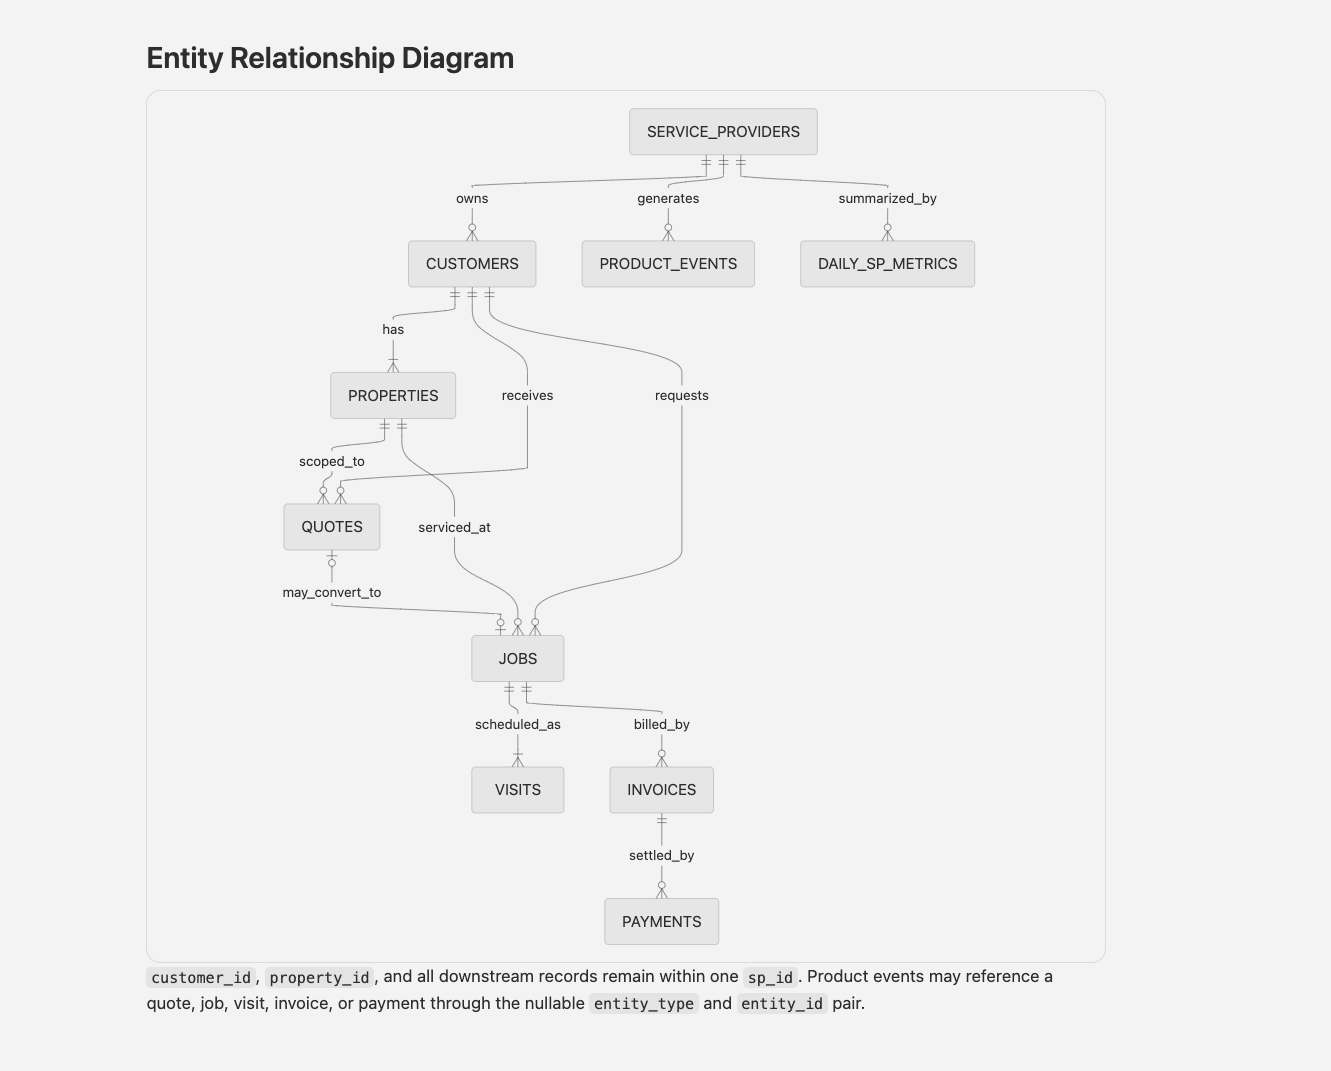

In [2]:
display(Image("../reference/ERD.png", width=640))

## 2. Integrity checks

In [3]:
supplied_zip = Path(os.environ.get("DATA_ZIP", "../../data.zip"))
report = audit.run(settings.data_dir, Path("../reference/DATA_DICTIONARY.csv"), quotes, supplied_zip)
report.groupby("check", sort=False)["ok"].agg(checks="size", passed="sum")

,checks,passed
check,,
matches zip,10,10
row count,10,10
columns,10,10
types parse,10,10
required present,10,10
key unique,10,10
links,16,16
quote rule,6,6
reconciles,4,4


In [4]:
report[report["check"].isin(["links", "reconciles"])]

,check,table,detail,ok
60,links,customers,sp_id -> service_providers: 0 orphans,True
61,links,properties,customer_id+sp_id -> customers: 0 orphans,True
62,links,quotes,customer_id+sp_id -> customers: 0 orphans,True
63,links,quotes,property_id+customer_id+sp_id -> properties: 0 orphans,True
64,links,jobs,property_id+customer_id+sp_id -> properties: 0 orphans,True
65,links,jobs,quote_id+customer_id+sp_id -> quotes: 0 orphans,True
66,links,visits,job_id+customer_id+property_id+sp_id -> jobs: 0 orphans,True
67,links,invoices,job_id+customer_id+property_id+sp_id -> jobs: 0 orphans,True
68,links,payments,invoice_id+customer_id+sp_id -> invoices: 0 orphans,True
69,links,product_events,sp_id -> service_providers: 0 orphans,True


Quotes created, sent and accepted per business per day match `daily_sp_metrics` exactly, which also
confirms that `decided_at` is the acceptance date.

## 3. Loading

Columns are read as text, then parsed strictly (`%Y-%m-%dT%H:%M:%S`); a malformed value stops the run.

In [5]:
quotes.head(3).T

,0,1,2
quote_id,QU020966,QU009646,QU009494
sp_id,SP0418,SP0198,SP0196
customer_id,CU009997,CU004785,CU004725
property_id,PR009997,PR004785,PR004725
workflow_type,recurring,emergency,recurring
created_at,2024-01-01 08:06:00,2024-01-01 10:15:00,2024-01-01 10:16:00
sent_at,2024-01-01 09:06:00,2024-01-01 12:15:00,2024-01-01 14:16:00
expires_at,2024-01-31 09:06:00,2024-01-31 12:15:00,2024-01-31 14:16:00
decided_at,2024-01-12 16:06:00,2024-01-03 16:15:00,2024-01-04 21:16:00
status,declined,accepted,accepted


| Derived column | Definition |
|---|---|
| `won` | 1 accepted; 0 declined or expired; blank for stale "open" |
| `hours_to_send` | hours from creating to sending the quote |
| `send_speed` | within a day / after a day |
| `resolved_at` | reply date, or expiry date if no reply |
| `days_to_decision` | days from sending to reply; blank if expired |

## 4. Preprocessing

In [6]:
explore.preprocessing_steps(quotes)

,rows
step,
"read quotes.csv as text, parse dates and amounts strictly",25000
"join customer and business on (sp_id, customer_id); all match",25000
"derive won, hours_to_send, log(1 + hours), send_speed, days_to_decision",25000
"drop the 1,444 stale 'open' quotes from learning and scoring",23556
"learning set on 2024-09-01: sent 45+ days earlier, ending on record",9077
"in the model: one-hot encode work and source, standardise log hours",9077


Joins: quotes to customers on (`sp_id`, `customer_id`), and to businesses on `sp_id`, so no record can
cross businesses. Jobs, visits, invoices and payments are never model inputs: they happen after a
quote is answered (a quote's job only exists once the quote is accepted), so using them would leak the
outcome. They appear only in the problem scan and the data checks.

## 5. Missing values

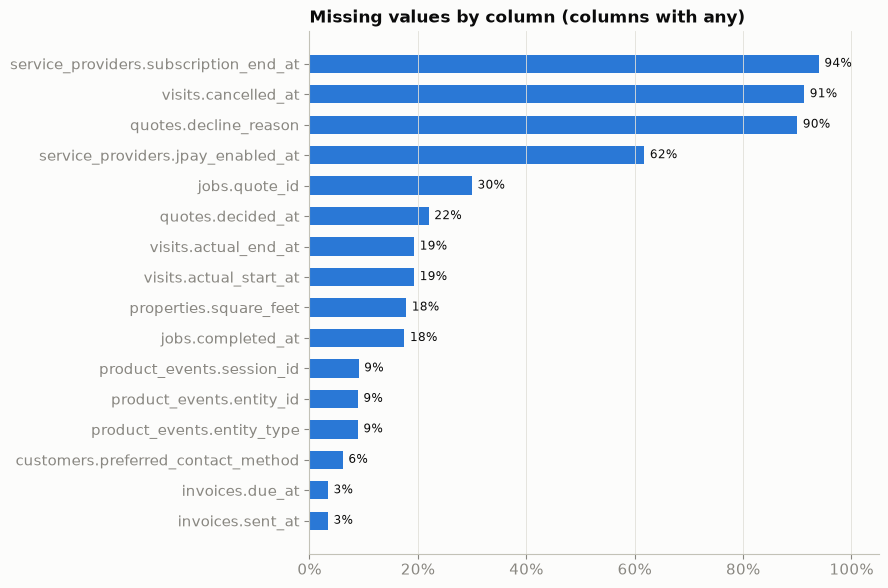

In [7]:
figures.eda_missing(settings.data_dir)

Mostly structural: `cancelled_at` exists only for cancelled visits, `decline_reason` only for
declines, `subscription_end_at` only for businesses that left. For quotes, only `decided_at` matters,
and it is empty exactly when a quote expired.

## 6. Sending time

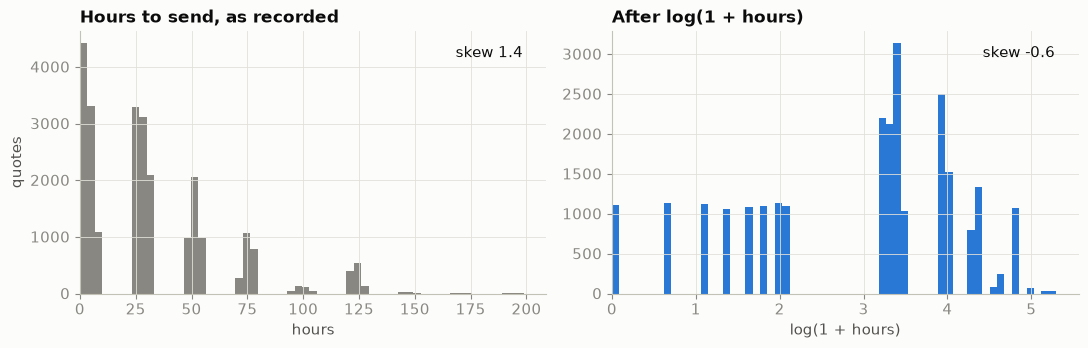

In [8]:
figures.eda_transform(quotes)

Quotes go out in daily batches with a long tail. `log(1 + hours)` cuts the skew from 1.4 to −0.6.

## 7. Facts about the extract

In [9]:
explore.data_facts(settings.data_dir, quotes)

latest payment or product event            19 Mar 2025
latest expiry date of any quote            23 Jan 2025
quotes still marked open                          1444
  of those, already past their expiry             100%
replies more than 45 days after sending              6
replies in total                                 19493
dtype: object

- Every quote expired before the last recorded activity, so "open" quotes are stale, not pending.
- Only 6 of 19,493 replies came after 45 days, so learning only from quotes 45+ days old loses almost nothing.

## 8. Quote amount as a measure of value

In [10]:
explore.quote_value_check(settings.data_dir, quotes)

,planned value / quote,invoiced value / quote
work,,
emergency job,1.025,1.022
one-off project,1.025,1.024
recurring service,1.024,1.023


Planned and invoiced job value are within 3% of the quote for every type of work.